#**Preparation of the data (detailed)**

**Loading the Dataset**

In [ ]:
import pandas as pd
df = pd.read_csv('/content/Bitcoin_5.csv', encoding = 'utf-8')

In [ ]:
df.head()

,Date,Close,Open,High,Low,Vol.,Change %
0,23-03-2025,"82,458.50","83,840.20","88,740.20","82,020.10",470.28K,-1.65%
1,16-03-2025,"83,840.50","84,341.30","87,419.00","81,171.30",384.35K,-0.59%
2,09-03-2025,"84,341.30","86,221.50","86,498.60","76,677.10",601.20K,-2.18%
3,02-03-2025,"86,221.90","86,065.70","94,986.50","81,617.00",767.22K,0.17%
4,23-02-2025,"86,071.60","96,556.20","96,655.20","78,329.80",858.44K,-10.86%


**Initial Inspection of the Data**

In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 261 entries, 0 to 260
Data columns (total 7 columns):
 #   Column    Non-Null Count  Dtype 
---  ------    --------------  ----- 
 0   Date      261 non-null    object
 1   Close     261 non-null    object
 2   Open      261 non-null    object
 3   High      261 non-null    object
 4   Low       261 non-null    object
 5   Vol.      261 non-null    object
 6   Change %  261 non-null    object
dtypes: object(7)
memory usage: 14.4+ KB


In [ ]:
#ensuring the date column is properly parsed
df['Date'] = pd.to_datetime(df['Date'])

<ipython-input-4-8f7b168b7f35>:2: UserWarning: Parsing dates in %d-%m-%Y format when dayfirst=False (the default) was specified. Pass `dayfirst=True` or specify a format to silence this warning.
  df['Date'] = pd.to_datetime(df['Date'])


In [ ]:
# Check for any unusual characters or formatting
print(df['Close'].unique())

# If you find problematic characters (like currency symbols or commas),
# you can remove or replace them using string manipulation before conversion:
df['Close'] = df['Close'].str.replace(',', '', regex=True)  # Example: Remove commas
df['Close'] = df['Close'].str.replace('$', '', regex=True)  # Example: Remove dollar signs

['82,458.50' '83,840.50' '84,341.30' '86,221.90' '86,071.60' '96,556.10'
 '97,573.40' '96,447.90' '1,00,648.00' '1,04,742.90' '1,04,536.90'
 '94,612.00' '98,219.90' '95,284.50' '97,253.30' '1,01,417.70' '99,837.00'
 '96,405.70' '97,699.00' '90,539.10' '76,700.30' '69,325.80' '67,086.80'
 '68,372.00' '63,205.10' '62,061.40' '65,866.50' '63,348.10' '59,995.40'
 '54,156.50' '58,978.60' '64,159.30' '59,483.10' '60,931.70' '60,696.70'
 '67,843.10' '67,148.50' '59,209.80' '58,259.20' '60,973.40' '64,261.00'
 '66,223.00' '69,310.10' '67,760.80' '69,284.40' '66,917.50' '60,826.60'
 '63,888.30' '63,456.80' '64,961.10' '63,849.90' '68,890.60' '69,611.50'
 '64,037.80' '65,314.20' '68,366.50' '61,994.50' '51,571.60' '51,646.00'
 '47,758.20' '43,005.70' '42,120.90' '41,695.40' '42,851.30' '43,967.90'
 '42,136.70' '43,710.40' '42,271.70' '43,718.40' '39,458.40' '37,787.00'
 '36,568.60' '37,150.50' '35,065.80' '34,082.60' '29,912.90' '26,852.80'
 '27,961.10' '26,962.70' '26,579.20' '26,562.00' '25,90

In [ ]:
#setting date as the index
# Check if 'Date' is already the index
if 'Date' in df.columns:
    df.set_index('Date', inplace=True)
    df.sort_index(inplace=True)
else:
    print("Date is already the index")

**Data Integrity and Missing Values Check**

In [ ]:
#identify missing values

missing_values = df.isnull().sum()
print(missing_values)

Close       0
Open        0
High        0
Low         0
Vol.        0
Change %    0
dtype: int64


**Feature Engineering**

To capture the  volatility clearly we create relevant financial features.

1. **Weekly Returns (Percentage Changes) :** measures how much the price moved from one week to the next.
2. **Log Returns :** normalize returns and help in volatility calculation
3. **Weekly Volatility (Rolling Std Deviation):** Measures volatility over a rolling period. (e.g. 4-week window is a monthly volatility)

In [ ]:
import numpy as np

df['Close'] = pd.to_numeric(df['Close'], errors='coerce')

df['Weekly_Return'] = df['Close'].pct_change()
df['Log_Return'] = np.log(df['Close'] / df['Close'].shift(1))
df['Weekly_Volatility'] = df['Log_Return'].rolling(window=4).std()

**Verifying Feature Creations**

In [ ]:
print(df[['Close', 'Weekly_Return', 'Log_Return', 'Weekly_Volatility']].head(10))

             Close  Weekly_Return  Log_Return  Weekly_Volatility
Date                                                            
2020-03-29  6857.4            NaN         NaN                NaN
2020-04-05  6867.8       0.001517    0.001515                NaN
2020-04-12  7230.8       0.052855    0.051506                NaN
2020-04-19  7540.4       0.042817    0.041926                NaN
2020-04-26  8966.3       0.189101    0.173198           0.074016
2020-05-03  9554.6       0.065612    0.063550           0.061080
2020-05-10  9379.5      -0.018326   -0.018496           0.080027
2020-05-17  9177.0      -0.021590   -0.021826           0.091668
2020-05-24  9692.5       0.056173    0.054652           0.045926
2020-05-31  9669.6      -0.002363   -0.002365           0.035474


**Outlier Detection and Management**

In [ ]:
threshold = 3.0
df['Weekly_Return_Outlier'] = (np.abs(df['Weekly_Return']) > threshold).astype(int)
# Assign the outliers to the 'outliers' variable
outliers = df[df['Weekly_Return_Outlier'] == 1]
print(outliers)

Empty DataFrame
Columns: [Close, Open, High, Low, Vol., Change %, Weekly_Return, Log_Return, Weekly_Volatility, Weekly_Return_Outlier]
Index: []


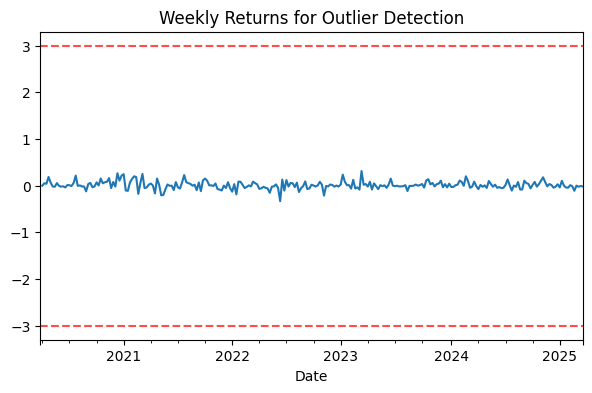

In [ ]:
import matplotlib.pyplot as plt

df['Weekly_Return'].plot(figsize=(7,4), title="Weekly Returns for Outlier Detection")
plt.axhline(y=threshold, color='r', linestyle='--', alpha=0.7)
plt.axhline(y=-threshold, color='r', linestyle='--', alpha=0.7)
plt.show()

**Thus we can conclude that there are no outliers and we can proceed.**



---



#**Exploratory Analysis and Volatility Understanding**

**Visualizaion of Bitcoin Price**

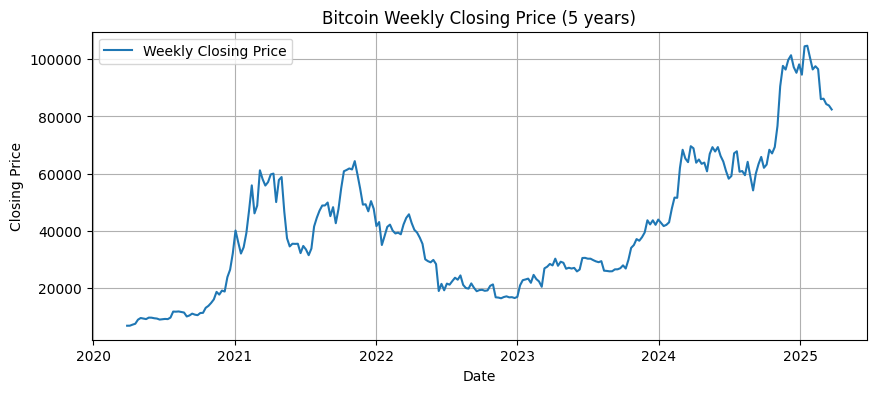

In [ ]:
plt.figure(figsize=(10,4))
plt.plot(df['Close'], label ='Weekly Closing Price')
plt.title('Bitcoin Weekly Closing Price (5 years)')
plt.xlabel('Date')
plt.ylabel('Closing Price')
plt.grid(True)
plt.legend()
plt.show()

**Weekly Returns and Log Return Analysis**

This is done to examine their distribution, volatility clustering and unusual behaviour.

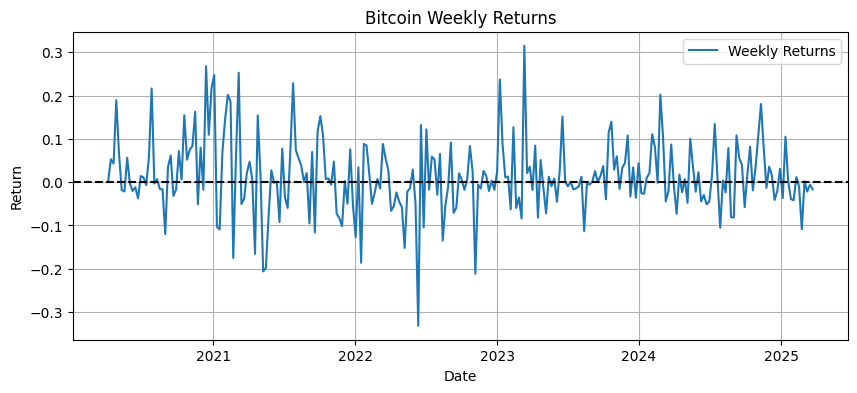

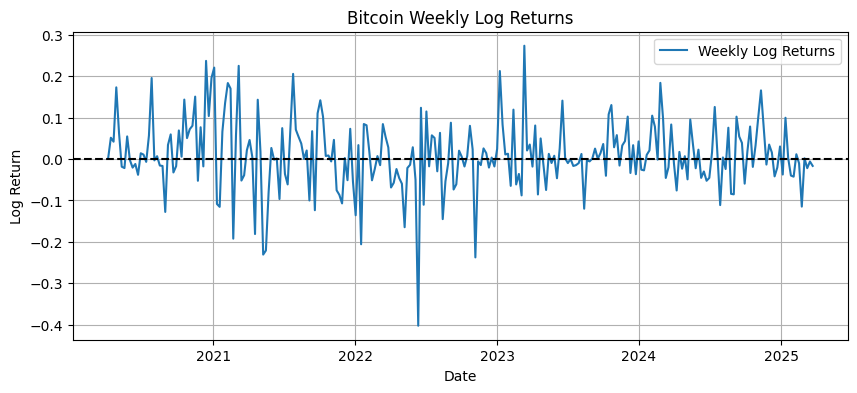

In [ ]:
plt.figure(figsize=(10,4))
plt.plot(df['Weekly_Return'], label='Weekly Returns')
plt.axhline(0, color='black', linestyle='--')
plt.title('Bitcoin Weekly Returns')
plt.xlabel('Date')
plt.ylabel('Return')
plt.grid(True)
plt.legend()
plt.show()

# Check log returns as well
plt.figure(figsize=(10,4))
plt.plot(df['Log_Return'], label='Weekly Log Returns')
plt.axhline(0, color='black', linestyle='--')
plt.title('Bitcoin Weekly Log Returns')
plt.xlabel('Date')
plt.ylabel('Log Return')
plt.grid(True)
plt.legend()
plt.show()

**Volatility Analysis**


*   **Rolling Volatility :** using a 4-week rolling period
*   **Volatility Distribution :** Visualize the distribution of volatility to assess how frequently high or low volatility occurs



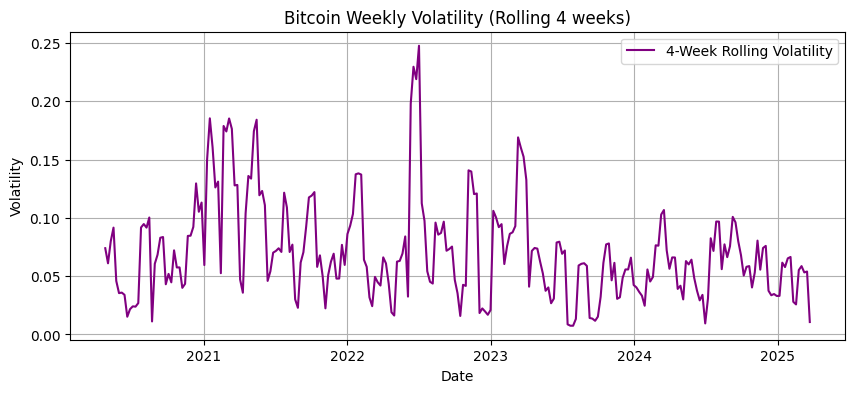

In [ ]:
#rolling volatility
plt.figure(figsize=(10,4))
plt.plot(df['Weekly_Volatility'], label='4-Week Rolling Volatility', color='purple')
plt.title('Bitcoin Weekly Volatility (Rolling 4 weeks)')
plt.xlabel('Date')
plt.ylabel('Volatility')
plt.grid(True)
plt.legend()
plt.show()

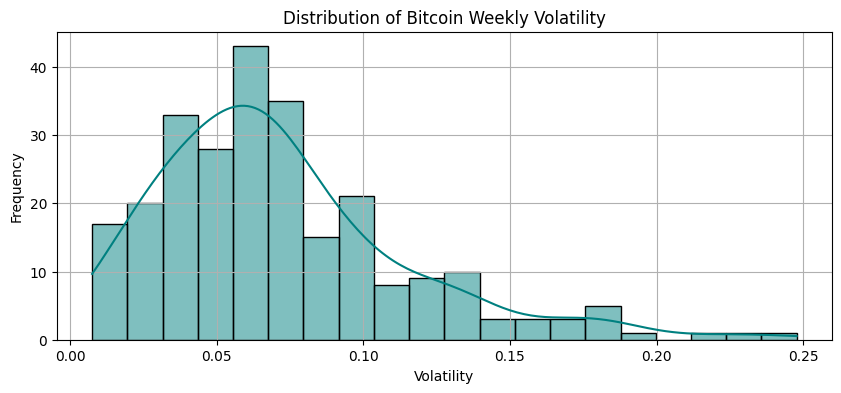

In [ ]:
import seaborn as sns

plt.figure(figsize=(10,4))
sns.histplot(df['Weekly_Volatility'].dropna(), bins=20, kde=True, color='teal')
plt.title('Distribution of Bitcoin Weekly Volatility')
plt.xlabel('Volatility')
plt.ylabel('Frequency')
plt.grid(True)
plt.show()

**Studying the Seasonal Patterns and Autocorrelations**


*   Check for seasonal volatility patterns
*   Autocorrelations of returns and volatility



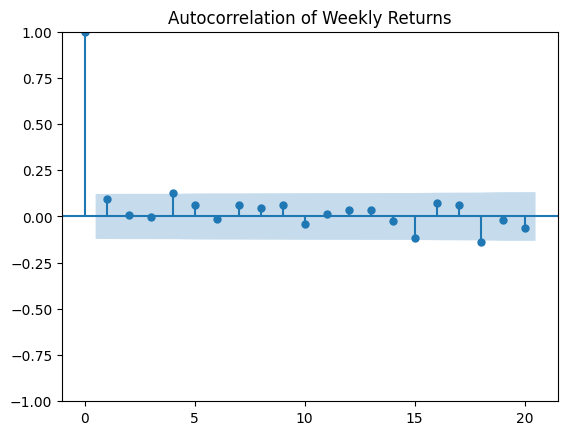

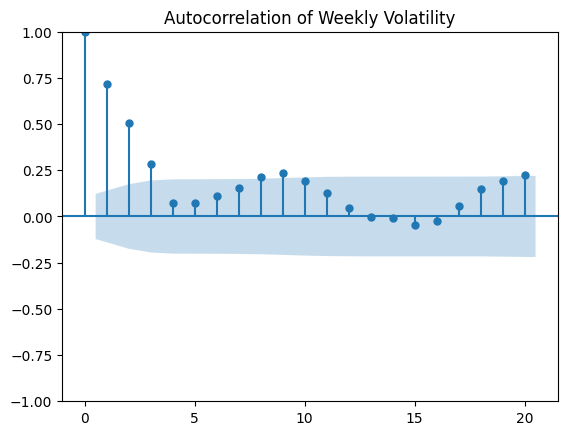

In [ ]:
from statsmodels.graphics.tsaplots import plot_acf

# Autocorrelation of Weekly Returns
plot_acf(df['Weekly_Return'].dropna(), lags=20)
plt.title('Autocorrelation of Weekly Returns')
plt.show()

# Autocorrelation of Volatility
plot_acf(df['Weekly_Volatility'].dropna(), lags=20)
plt.title('Autocorrelation of Weekly Volatility')
plt.show()

**Statistical Summary**

In [ ]:
print(df[['Weekly_Return', 'Weekly_Volatility']].describe())

       Weekly_Return  Weekly_Volatility
count     260.000000         257.000000
mean        0.013202           0.071297
std         0.085379           0.042803
min        -0.331541           0.007506
25%        -0.030204           0.041977
50%         0.005125           0.062489
75%         0.055955           0.091693
max         0.314968           0.247762


#**Stationarity Testing (ADF Test)**

In [ ]:
from statsmodels.tsa.stattools import adfuller

#adf test for log returns
adf_result = adfuller(df['Log_Return'].dropna())
print(f'ADF Statistic: {adf_result[0]}')
print(f'p-value: {adf_result[1]}')
print(f"Critical Values:")
for key, value in adf_result[4].items():
    print(f"\t{key}: {value}")

ADF Statistic: -14.72440059262253
p-value: 2.7203162604495947e-27
Critical Values:
	1%: -3.4558530692911504
	5%: -2.872764881778665
	10%: -2.572751643088207


Interpretetion : The ADF Statistic shows that clear rejection of non stationarity. A very small p-value almost nearing zero indicates that the series is stationary, confirming the results we typically expect with financial log returns.

#**GARCH Modelling for volatility forecasting**

In [ ]:
!pip install arch

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 985.3/985.3 kB 18.2 MB/s eta 0:00:00


**GARCH(1,1) Model Implementation**

In [ ]:
from arch import arch_model

log_returns = df['Log_Return'].dropna()
model = arch_model(log_returns, vol='GARCH', p=1, q=1, dist='normal')
model_results = model.fit(disp="off") #hides detailed iterations

print(model_results.summary())

                     Constant Mean - GARCH Model Results                      
Dep. Variable:             Log_Return   R-squared:                       0.000
Mean Model:             Constant Mean   Adj. R-squared:                  0.000
Vol Model:                      GARCH   Log-Likelihood:                278.657
Distribution:                  Normal   AIC:                          -549.314
Method:            Maximum Likelihood   BIC:                          -535.071
                                        No. Observations:                  260
Date:                Thu, Apr 10 2025   Df Residuals:                      259
Time:                        02:34:13   Df Model:                            1
                                 Mean Model                                 
                 coef    std err          t      P>|t|      95.0% Conf. Int.
----------------------------------------------------------------------------
mu             0.0110  4.650e-03      2.360  1.829e-02 [1.

/usr/local/lib/python3.11/dist-packages/arch/univariate/base.py:309: DataScaleWarning: y is poorly scaled, which may affect convergence of the optimizer when
estimating the model parameters. The scale of y is 0.007145. Parameter
estimation work better when this value is between 1 and 1000. The recommended
rescaling is 10 * y.

This warning can be disabled by either rescaling y before initializing the
model or by setting rescale=False.

  warnings.warn(


In [ ]:
# GARCH(1,1) - Normal Distribution
garch_normal = arch_model(returns, vol='GARCH', p=1, o=0, q=1, dist='normal')
res_garch_normal = garch_normal.fit(disp='off')
print("\n=== GARCH(1,1) with Normal Distribution ===")
print(res_garch_normal.summary())

# GARCH(1,1) - Student's t Distribution
garch_t = arch_model(returns, vol='GARCH', p=1, o=0, q=1, dist='t')
res_garch_t = garch_t.fit(disp='off')
print("\n=== GARCH(1,1) with Student's t Distribution ===")
print(res_garch_t.summary())

# EGARCH(1,1) - Normal Distribution
egarch_normal = arch_model(returns, vol='EGARCH', p=1, o=1, q=1, dist='normal')
res_egarch_normal = egarch_normal.fit(disp='off')
print("\n=== EGARCH(1,1) with Normal Distribution ===")
print(res_egarch_normal.summary())

# EGARCH(1,1) - Student's t Distribution
egarch_t = arch_model(returns, vol='EGARCH', p=1, o=1, q=1, dist='t')
res_egarch_t = egarch_t.fit(disp='off')
print("\n=== EGARCH(1,1) with Student's t Distribution ===")
print(res_egarch_t.summary())


NameError: name 'returns' is not defined

In [ ]:
# GARCH(1,1) - Normal Distribution
garch_normal = arch_model(log_returns, vol='GARCH', p=1, o=0, q=1, dist='normal') # Changed 'returns' to 'log_returns'
res_garch_normal = garch_normal.fit(disp='off')
print("\n=== GARCH(1,1) with Normal Distribution ===")
print(res_garch_normal.summary())

# GARCH(1,1) - Student's t Distribution
garch_t = arch_model(log_returns, vol='GARCH', p=1, o=0, q=1, dist='t') # Changed 'returns' to 'log_returns'
res_garch_t = garch_t.fit(disp='off')
print("\n=== GARCH(1,1) with Student's t Distribution ===")
print(res_garch_t.summary())

# EGARCH(1,1) - Normal Distribution
egarch_normal = arch_model(log_returns, vol='EGARCH', p=1, o=1, q=1, dist='normal') # Changed 'returns' to 'log_returns'
res_egarch_normal = egarch_normal.fit(disp='off')
print("\n=== EGARCH(1,1) with Normal Distribution ===")
print(res_egarch_normal.summary())

# EGARCH(1,1) - Student's t Distribution
egarch_t = arch_model(log_returns, vol='EGARCH', p=1, o=1, q=1, dist='t') # Changed 'returns' to 'log_returns'
res_egarch_t = egarch_t.fit(disp='off')
print("\n=== EGARCH(1,1) with Student's t Distribution ===")
print(res_egarch_t.summary())

/usr/local/lib/python3.11/dist-packages/arch/univariate/base.py:309: DataScaleWarning: y is poorly scaled, which may affect convergence of the optimizer when
estimating the model parameters. The scale of y is 0.007145. Parameter
estimation work better when this value is between 1 and 1000. The recommended
rescaling is 10 * y.

This warning can be disabled by either rescaling y before initializing the
model or by setting rescale=False.

  warnings.warn(
/usr/local/lib/python3.11/dist-packages/arch/univariate/base.py:309: DataScaleWarning: y is poorly scaled, which may affect convergence of the optimizer when
estimating the model parameters. The scale of y is 0.007145. Parameter
estimation work better when this value is between 1 and 1000. The recommended
rescaling is 10 * y.

This warning can be disabled by either rescaling y before initializing the
model or by setting rescale=False.

  warnings.warn(
/usr/local/lib/python3.11/dist-packages/arch/univariate/base.py:309: DataScaleWarning:


=== GARCH(1,1) with Normal Distribution ===
                     Constant Mean - GARCH Model Results                      
Dep. Variable:             Log_Return   R-squared:                       0.000
Mean Model:             Constant Mean   Adj. R-squared:                  0.000
Vol Model:                      GARCH   Log-Likelihood:                278.657
Distribution:                  Normal   AIC:                          -549.314
Method:            Maximum Likelihood   BIC:                          -535.071
                                        No. Observations:                  260
Date:                Thu, Apr 10 2025   Df Residuals:                      259
Time:                        02:36:25   Df Model:                            1
                                 Mean Model                                 
                 coef    std err          t      P>|t|      95.0% Conf. Int.
----------------------------------------------------------------------------
mu           

/usr/local/lib/python3.11/dist-packages/arch/univariate/base.py:768: ConvergenceWarning: The optimizer returned code 9. The message is:
Iteration limit reached
See scipy.optimize.fmin_slsqp for code meaning.

  warnings.warn(


In [ ]:
print("\nComparison of Model Criteria:")
print("-------------------------------------------------------------------")
print(f"{'Model':<35} {'AIC':>2} {'BIC':>12} {'LogLk':>12}")
print("-------------------------------------------------------------------")
print(f"GARCH(1,1) Normal           {res_garch_normal.aic:12.2f} {res_garch_normal.bic:12.2f} {res_garch_normal.loglikelihood:12.2f}")
print(f"GARCH(1,1) Student's t      {res_garch_t.aic:12.2f} {res_garch_t.bic:12.2f} {res_garch_t.loglikelihood:12.2f}")
print(f"EGARCH(1,1) Normal          {res_egarch_normal.aic:12.2f} {res_egarch_normal.bic:12.2f} {res_egarch_normal.loglikelihood:12.2f}")
print(f"EGARCH(1,1) Student's t     {res_egarch_t.aic:12.2f} {res_egarch_t.bic:12.2f} {res_egarch_t.loglikelihood:12.2f}")
print("--------------------------------------------------------------------")


Comparison of Model Criteria:
-------------------------------------------------------------------
Model                               AIC          BIC        LogLk
-------------------------------------------------------------------
GARCH(1,1) Normal                -549.31      -535.07       278.66
GARCH(1,1) Student's t           -575.82      -558.02       292.91
EGARCH(1,1) Normal               -553.49      -535.69       281.75
EGARCH(1,1) Student's t          -578.92      -557.56       295.46
--------------------------------------------------------------------


**Forecasting the next 8-weeks Volatility**

In [ ]:
forecast_horizon = 8
volatility_forecast = model_results.forecast(horizon=forecast_horizon, reindex=False)
print("Volatility Forecast (next 8-weeks): ")
print(np.sqrt(volatility_forecast.variance.iloc[-1]))

Volatility Forecast (next 8-weeks): 
h.1    0.067610
h.2    0.067903
h.3    0.068190
h.4    0.068472
h.5    0.068747
h.6    0.069017
h.7    0.069282
h.8    0.069541
Name: 2025-03-23 00:00:00, dtype: float64


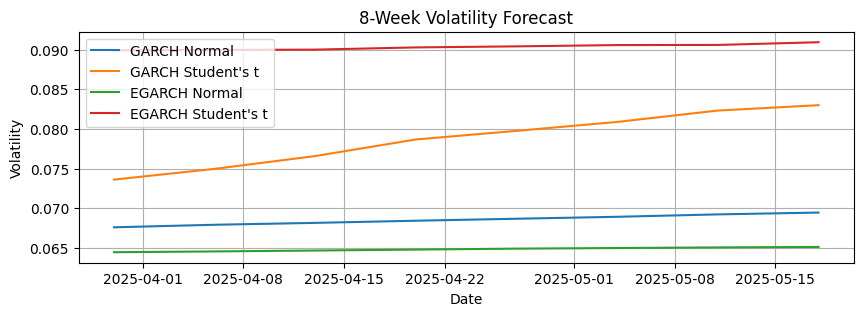

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from arch import arch_model

# Assuming 'log_returns' is already defined as in your previous code

# Forecast horizon
forecast_horizon = 8

# Models and their forecasts
models = {
    "GARCH Normal": res_garch_normal,
    "GARCH Student's t": res_garch_t,
    "EGARCH Normal": res_egarch_normal,
    "EGARCH Student's t": res_egarch_t
}

forecasts = {}
for model_name, model in models.items():
    # Specify method='simulation' for horizons > 1
    forecast = model.forecast(horizon=forecast_horizon, method='simulation', reindex=False)
    forecasts[model_name] = np.sqrt(forecast.variance.iloc[-1])  # Take the square root for volatility

# Create a DataFrame for plotting
forecast_df = pd.DataFrame(forecasts)
forecast_df.index = pd.date_range(start=df.index[-1] + pd.DateOffset(weeks=1), periods=forecast_horizon, freq='W')  # Set appropriate date range

# Plotting the forecasts
plt.figure(figsize=(10,3))
for model_name in forecasts:
    plt.plot(forecast_df.index, forecast_df[model_name], label=model_name)

plt.title("8-Week Volatility Forecast")
plt.xlabel("Date")
plt.ylabel("Volatility")
plt.legend()
plt.grid(True)
plt.show()

In [ ]:
import numpy as np
import pandas as pd
from arch import arch_model

# Assuming 'log_returns' is your log return series
# Assuming you have already fitted the models as 'res_garch_normal', 'res_garch_t', 'res_egarch_normal'

forecast_horizon = 8  # Forecast for the next 8 weeks

# Store forecasts in a dictionary
volatility_forecasts = {}

# GARCH(1,1) - Normal Distribution
forecast = res_garch_normal.forecast(horizon=forecast_horizon, method='simulation', reindex=False)
volatility_forecasts["GARCH Normal"] = np.sqrt(forecast.variance.iloc[-1])

# GARCH(1,1) - Student's t Distribution
forecast = res_garch_t.forecast(horizon=forecast_horizon, method='simulation', reindex=False)
volatility_forecasts["GARCH Student's t"] = np.sqrt(forecast.variance.iloc[-1])

# EGARCH(1,1) - Normal Distribution
forecast = res_egarch_normal.forecast(horizon=forecast_horizon, method='simulation', reindex=False)
volatility_forecasts["EGARCH Normal"] = np.sqrt(forecast.variance.iloc[-1])

# EGARCH(1,1) - T Distribution
forecast = res_egarch_t.forecast(horizon=forecast_horizon, method='simulation', reindex=False)
volatility_forecasts["EGARCH Student's T"] = np.sqrt(forecast.variance.iloc[-1])

# Print the volatility forecasts
for model_name, forecast_values in volatility_forecasts.items():
    print(f"\nVolatility Forecast for {model_name} (next 8 weeks):")
    print(forecast_values)


Volatility Forecast for GARCH Normal (next 8 weeks):
h.1    0.067610
h.2    0.067867
h.3    0.068139
h.4    0.068455
h.5    0.068787
h.6    0.069100
h.7    0.069378
h.8    0.069668
Name: 2025-03-23 00:00:00, dtype: float64

Volatility Forecast for GARCH Student's t (next 8 weeks):
h.1    0.073620
h.2    0.074551
h.3    0.075650
h.4    0.076786
h.5    0.078176
h.6    0.079010
h.7    0.079659
h.8    0.080565
Name: 2025-03-23 00:00:00, dtype: float64

Volatility Forecast for EGARCH Normal (next 8 weeks):
h.1    0.064470
h.2    0.064574
h.3    0.064637
h.4    0.064776
h.5    0.064856
h.6    0.064948
h.7    0.065011
h.8    0.065061
Name: 2025-03-23 00:00:00, dtype: float64

Volatility Forecast for EGARCH Student's T (next 8 weeks):
h.1    0.089902
h.2    0.089945
h.3    0.090243
h.4    0.090141
h.5    0.090119
h.6    0.090357
h.7    0.090657
h.8    0.090798
Name: 2025-03-23 00:00:00, dtype: float64
